# تحليل مجموعة بيانات Iris

يشرح هذا الدفتر خطوات استكشاف بيانات أزهار Iris باستخدام `Pandas`: فحص البيانات وجودتها، وحساب الإحصائيات، وتصفية الصفوف وترتيبها، وتصدير النتائج إلى ملفات CSV، ثم عرض رسم بياني.

**طريقة الاستخدام:** شغّل الخلايا بالترتيب من الأعلى إلى الأسفل. يجب أن يكون ملف البيانات موجودًا في `data/iris.csv`.

## 1. تحميل مجموعة البيانات

نقرأ الملف `data/iris.csv` ونخزّن البيانات في `DataFrame` اسمه `df`، ثم نعرض أول خمسة صفوف.

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("data/iris.csv")
if not data_path.exists():
    raise FileNotFoundError("Could not find data/iris.csv. Place iris.csv inside the project data folder, then run this notebook again.")
df = pd.read_csv(data_path)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. استكشاف البيانات والتحقق من جودتها

نفحص أبعاد مجموعة البيانات، وأسماء الأعمدة، وأنواع البيانات، وآخر خمسة صفوف. كما نتحقق من وجود قيم مفقودة وصفوف مكررة.

In [2]:
print("أبعاد البيانات (صفوف، أعمدة):", df.shape)
print("أسماء الأعمدة:", df.columns.tolist())

print("\nأنواع البيانات:")
print(df.dtypes)

print("\nآخر خمسة صفوف:")
display(df.tail())

print("\nالقيم المفقودة لكل عمود:")
print(df.isnull().sum())

print("\nعدد الصفوف المكررة:", df.duplicated().sum())

أبعاد البيانات (صفوف، أعمدة): (150, 5)
أسماء الأعمدة: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

أنواع البيانات:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

آخر خمسة صفوف:


,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica



القيم المفقودة لكل عمود:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

عدد الصفوف المكررة: 1


## 3. استكشاف أنواع الزهور والقياسات

نعرض أنواع الزهور المختلفة وعدد السجلات لكل نوع، ثم نحسب متوسط `sepal_length` وأكبر قيمة لـ `petal_length` وأصغر قيمة لـ `sepal_width`.

In [3]:
print("Unique species:")
print(df["species"].unique())

print("Species counts:")
print(df["species"].value_counts())

print("Average sepal length:", df["sepal_length"].mean())
print("Maximum petal length:", df["petal_length"].max())
print("Minimum sepal width:", df["sepal_width"].min())

Unique species:
<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Average sepal length: 5.843333333333334
Maximum petal length: 6.9
Minimum sepal width: 2.0


## 4. الإحصائيات الملخّصة حسب نوع الزهرة

نجمع السجلات حسب العمود `species`، ثم نحسب متوسط كل عمود رقمي لكل نوع من أنواع الزهور.

In [4]:
species_summary = df.groupby("species").mean(numeric_only=True)

species_summary

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


## 5. الإحصائيات الوصفية العامة

نستخدم `describe()` لتلخيص الأعمدة الرقمية، بما في ذلك عدد القيم (`count`)، والمتوسط (`mean`)، والانحراف المعياري (`std`)، والربيعات، وأقل قيمة (`min`)، وأعلى قيمة (`max`).

In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 6. تصفية مجموعة البيانات

### 6.1 طول السبل أكبر من 6

نعرض الصفوف التي تكون فيها قيمة `sepal_length` أكبر من 6. ينتج عن هذا الشرط 61 صفًا في مجموعة البيانات المستخدمة.

In [6]:
df[df["sepal_length"] > 6]

,sepal_length,sepal_width,petal_length,petal_width,species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
54,6.5,2.8,4.6,1.5,versicolor
56,6.3,3.3,4.7,1.6,versicolor
...,...,...,...,...,...
144,6.7,3.3,5.7,2.5,virginica
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica


### 6.2 عرض البتلة أكبر من 1.5

نعرض الصفوف التي تكون فيها قيمة `petal_width` أكبر من 1.5.

In [7]:
df[df["petal_width"] > 1.5]

,sepal_length,sepal_width,petal_length,petal_width,species
56,6.3,3.3,4.7,1.6,versicolor
70,5.9,3.2,4.8,1.8,versicolor
77,6.7,3.0,5.0,1.7,versicolor
83,6.0,2.7,5.1,1.6,versicolor
85,6.0,3.4,4.5,1.6,versicolor
100,6.3,3.3,6.0,2.5,virginica
101,5.8,2.7,5.1,1.9,virginica
102,7.1,3.0,5.9,2.1,virginica
103,6.3,2.9,5.6,1.8,virginica
104,6.5,3.0,5.8,2.2,virginica


### 6.3 زهور Setosa فقط

نعرض الصفوف التي تكون فيها قيمة `species` مساوية لـ `setosa`.

In [8]:
df[df["species"] == "setosa"]

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


## 7. مقارنة متوسط طول البتلة حسب نوع الزهرة

نحسب متوسط `petal_length` لكل نوع، ثم نحدد النوع صاحب أعلى متوسط. النتيجة هي `virginica`.

In [9]:
df.groupby("species")["petal_length"].mean().idxmax()

'virginica'

## 8. ترتيب مجموعة البيانات

نرتب الصفوف حسب `sepal_length` ترتيبًا تنازليًا، بحيث تظهر الزهور ذات السبل الأطول أولًا.

In [10]:
df.sort_values(by="sepal_length", ascending=False)

,sepal_length,sepal_width,petal_length,petal_width,species
131,7.9,3.8,6.4,2.0,virginica
122,7.7,2.8,6.7,2.0,virginica
118,7.7,2.6,6.9,2.3,virginica
117,7.7,3.8,6.7,2.2,virginica
135,7.7,3.0,6.1,2.3,virginica
...,...,...,...,...,...
41,4.5,2.3,1.3,0.3,setosa
42,4.4,3.2,1.3,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
38,4.4,3.0,1.3,0.2,setosa


## 9. تصدير النتائج إلى ملفات CSV

ننشىء مجلد `output` إذا لم يكن موجودًا، ونحسب متوسط القياسات حسب نوع الزهرة، ثم نحفظ الملخص في الملف `output/species_summary.csv`.

In [16]:
import os

os.makedirs("output", exist_ok=True)

species_summary = df.groupby("species").describe()

species_summary.to_csv(
    "output/species_summary.csv"
)
display(species_summary)

sepal_length                                              \
                  count   mean       std  min    25%  50%  75%  max   
species                                                               
setosa             50.0  5.006  0.352490  4.3  4.800  5.0  5.2  5.8   
versicolor         50.0  5.936  0.516171  4.9  5.600  5.9  6.3  7.0   
virginica          50.0  6.588  0.635880  4.9  6.225  6.5  6.9  7.9   

           sepal_width         ... petal_length      petal_width         \
                 count   mean  ...          75%  max       count   mean   
species                        ...                                        
setosa            50.0  3.428  ...        1.575  1.9        50.0  0.246   
versicolor        50.0  2.770  ...        4.600  5.1        50.0  1.326   
virginica         50.0  2.974  ...        5.875  6.9        50.0  2.026   

                                               
                 std  min  25%  50%  75%  max  
species                                        
setosa      0.105386  0.1  0.2  0.2  0.3  0.6  
versicolor  0.197753  1.0  1.2  1.3  1.5  1.8  
virginica   0.274650  1.4  1.8  2.0  2.3  2.5  

[3 rows x 32 columns]

نحفظ السجلات التي تحقق الشرط `sepal_length > 6` في الملف `output/filtered_iris.csv`.

In [12]:
filtered_iris = df[df["sepal_length"] > 6]
filtered_iris.to_csv("output/filtered_iris.csv", index=False)
print("تم حفظ البيانات المصفّاة في output/filtered_iris.csv")
print("أبعاد البيانات المصفّاة:", filtered_iris.shape)
display(filtered_iris.head())

تم حفظ البيانات المصفّاة في output/filtered_iris.csv
أبعاد البيانات المصفّاة: (61, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
54,6.5,2.8,4.6,1.5,versicolor
56,6.3,3.3,4.7,1.6,versicolor


### التحقق من الملفات المصدّرة

نتأكد من أسماء الملفات الموجودة داخل مجلد `output` بعد التصدير.


## 10. عرض متوسط طول البتلة في رسم بياني

يقارن الرسم البياني متوسط طول البتلة للأنواع الثلاثة. يظهر لكل نوع مؤشر بلون مختلف، ويكون متوسط `petal_length` الأعلى لدى `virginica`.

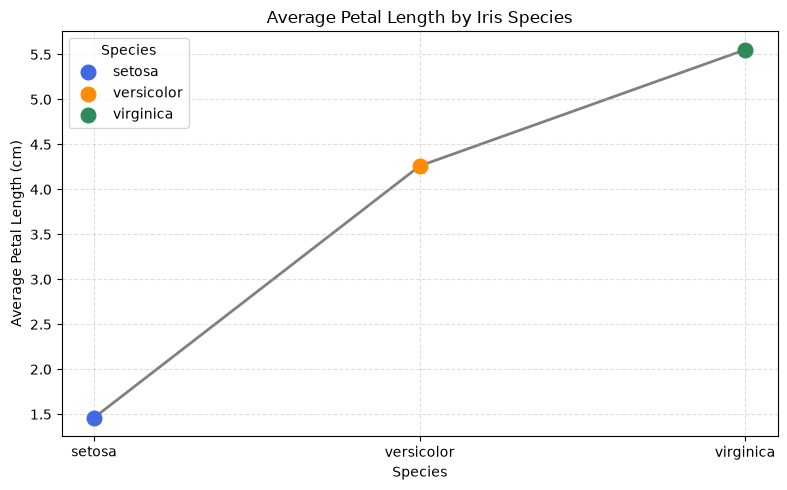

In [13]:
import matplotlib.pyplot as plt

species_avg = df.groupby("species")["petal_length"].mean().reindex(["setosa", "versicolor", "virginica"])
colors = {"setosa": "royalblue", "versicolor": "darkorange", "virginica": "seagreen"}

plt.figure(figsize=(8, 5))
plt.plot(species_avg.index, species_avg.values, color="gray", linestyle="-", linewidth=2, zorder=1)
for species, avg in species_avg.items():
    plt.scatter(species, avg, color=colors[species], s=110, label=species, zorder=2)

plt.title("Average Petal Length by Iris Species")
plt.xlabel("Species")
plt.ylabel("Average Petal Length (cm)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Species")
plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path

print("ملفات مجلد output:")
for file in sorted(Path("output").glob("*.csv")):
    print(f"- {file} | الحجم: {file.stat().st_size} بايت")


ملفات مجلد output:
- output\filtered_iris.csv | الحجم: 1726 بايت
- output\species_summary.csv | الحجم: 189 بايت
